# Analysis (base)

Device-agnostic launch point over `hera.analysis` — the data layer for
spxtr/measureme `sweep` runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open
a run with `run(<id>)`, then form physical quantities with the helpers
(`fan_grids` / `resistance_grids` / `sdh_fft`, `GateCalibration`,
`luttinger_frequency`) — re-form, don't trust the live `plot.png`. Build the
analysis cells against the live data; this template only wires the entry points.

`hera-mksession` copies this per session; **hera-session** fills the geometry
slot below from `device_card.md` and marks filled values `# <-- validate`.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [ ]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry. hera-session fills the gate-stack thicknesses from the
# device card (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Mark each filled value `# <-- validate`.
# PLACEHOLDER numbers below.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Run 1 — 0 T TG–BG gate map (raw re-formed Rxx)

Raw before interpretation. Per-channel Rxx = sr_X / I_drain (I_drain = sr0_X / −1e6),
re-formed from the TSV at native grid (37 BG × 131 TG), not the monitor PNG. CNP ridge
visible as the bright diagonal; it broadens/brightens toward the high-|D| corners (a
D-induced gap at charge neutrality) and thins to a faint line at center (D≈0). Lock-ins
clip at the 2e-5 overload ceiling (≈4.37 kΩ) on the gapped CNP — so CNP-R at high |D| is
a lower bound here; ridge *position* is unaffected. (Run 1, slug `gatemap`.)


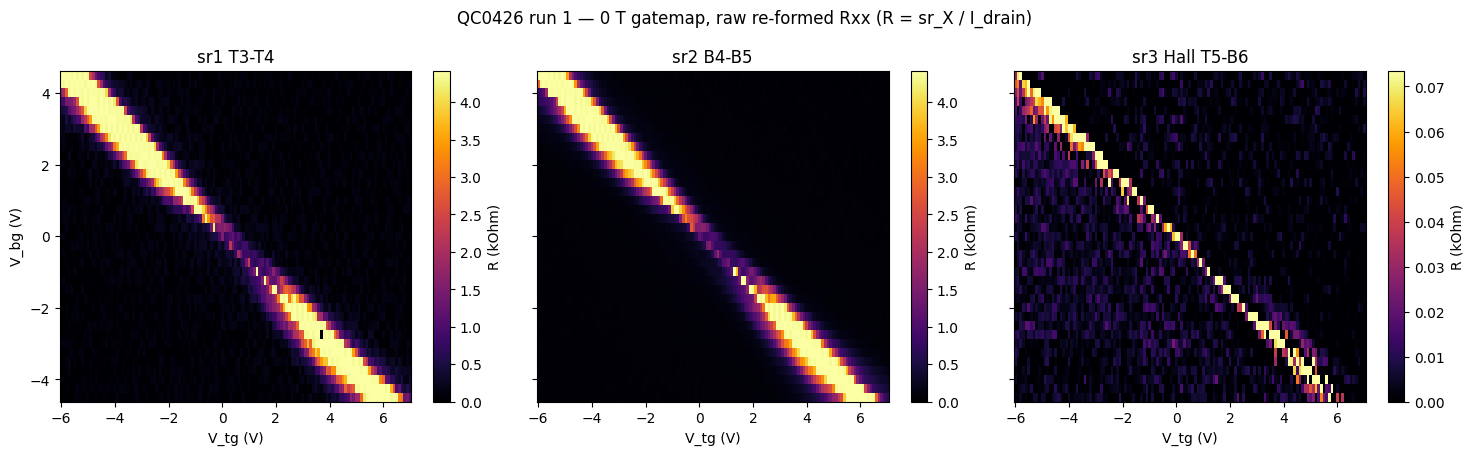

Note: CNP ridge broadens/brightens toward high-|D| corners (D-induced gap), thins to faint
line at center (D~0). Lock-ins clip at 4.37 kOhm (sens 2e-5 overload) on the gapped CNP;
CNP-R(D) from this map is a LOWER BOUND at high |D|. Ridge POSITION unaffected.


In [1]:
# Run 1 — 0 T TG-BG gatemap: raw re-formed per-channel Rxx maps (TSV, not monitor PNG)
import numpy as np, matplotlib.pyplot as plt
from hera.analysis import open_run
run = open_run("data/1")
bg = run.col('k_2400_volt'); tg = run.col('DC_bias'); I = run.col('sr0_X')/(-1e6)
chans = {'sr1 T3-T4': run.col('sr1_X')/I, 'sr2 B4-B5': run.col('sr2_X')/I, 'sr3 Hall T5-B6': run.col('sr3_X')/I}
BG = np.unique(np.round(bg,3)); TG = np.unique(np.round(tg,3))
bi = {b:i for i,b in enumerate(BG)}; ti = {t:i for i,t in enumerate(TG)}
def grid(v):
    g = np.full((len(BG),len(TG)), np.nan)
    for k in range(len(v)): g[bi[round(bg[k],3)], ti[round(tg[k],3)]] = v[k]
    return g
fig, ax = plt.subplots(1,3, figsize=(15,4.6), sharex=True, sharey=True)
for a,(nm,v) in zip(ax, chans.items()):
    g = grid(v)/1e3
    im = a.pcolormesh(TG, BG, g, shading='nearest', cmap='inferno', vmin=0, vmax=np.nanpercentile(g,98))
    a.set_title(nm); a.set_xlabel('V_tg (V)'); plt.colorbar(im, ax=a, label='R (kOhm)')
ax[0].set_ylabel('V_bg (V)')
plt.suptitle('QC0426 run 1 — 0 T gatemap, raw re-formed Rxx (R = sr_X / I_drain)')
plt.tight_layout(); plt.show()
print("Note: CNP ridge broadens/brightens toward high-|D| corners (D-induced gap), thins to faint")
print("line at center (D~0). Lock-ins clip at 4.37 kOhm (sens 2e-5 overload) on the gapped CNP;")
print("CNP-R(D) from this map is a LOWER BOUND at high |D|. Ridge POSITION unaffected.")


## Run 1 — CNP-line fit and (n, D) calibration

Per-channel CNP ridge (plateau-center argmax, edge-clipped rows dropped) → linear fit;
slope = −c_bg/c_tg. Both Rxx channels agree to 0.05% and match the geometry prior (1.300)
to 0.7% — one device calibration. D=0 located from the CNP-R minimum (symmetric D-gap),
not assumed. **Two-tier provenance: ratio data-calibrated; absolute n,D scale geometry-prior**
(t_tg=15.6 nm), pending a quantum-Hall lever-arm upgrade. Output feeds every downstream
(n,D) claim (spot checks, fan). (`cnp-and-dline-calibration`.)


In [2]:
# Run 1 — CNP-line fit + (n,D) calibration (cnp-and-dline-calibration)
import numpy as np
from hera.analysis import open_run, GateCalibration
run = open_run("data/1")
bg = run.col('k_2400_volt'); tg = run.col('DC_bias'); I = run.col('sr0_X')/(-1e6)
R1 = run.col('sr1_X')/I; R2 = run.col('sr2_X')/I
TG_LO, TG_HI, RAIL = -6.0, 7.0, 4.2e3
def ridge(R):
    rows = np.unique(np.round(bg,3)); bb=[];vv=[];pk=[];edge=[]
    for b in rows:
        m = np.abs(bg-b)<1e-4
        if m.sum()<20: continue
        t=tg[m]; r=R[m]; o=np.argsort(t); t=t[o]; r=r[o]
        top = t[r >= 0.92*r.max()]          # plateau center (robust to clipped flat-tops)
        bb.append(b); vv.append(np.median(top)); pk.append(r.max())
        edge.append(top.min()<=TG_LO+0.4 or top.max()>=TG_HI-0.4)
    return map(np.array,(bb,vv,pk,edge))
b1,v1,pk1,e1 = ridge(R1); b2,v2,pk2,e2 = ridge(R2)
for nm,b,v,e in [('sr1 T3-T4',b1,v1,e1),('sr2 B4-B5',b2,v2,e2)]:
    p = np.polyfit(b[~e], v[~e], 1)
    print(f"{nm}: V_tg = {p[0]:+.4f} V_bg {p[1]:+.4f}   c_bg/c_tg = {-p[0]:.4f}  (rows {(~e).sum()}/{len(b)})")
B = np.concatenate([b1[~e1],b2[~e2]]); V = np.concatenate([v1[~e1],v2[~e2]])
slope,intc = np.polyfit(B,V,1); ratio = -slope
uc = pk1<RAIL; jmin = np.argmin(pk1[uc]); bgD0=float(b1[uc][jmin]); vtgD0=float(v1[uc][jmin])
print(f"\nPOOLED device CNP fit: V_tg = {slope:+.4f} V_bg {intc:+.4f}   c_bg/c_tg = {ratio:.4f}  (geom prior 1.300)")
print(f"D=0 located at CNP-R minimum: (V_tg, V_bg) = ({vtgD0:+.2f}, {bgD0:+.2f})  -> D_offset locator")
# refined calibration: data ratio, geometry scale-anchor (t_tg=15.6 nm hBN)
t_tg = 15.6e-9; t_bg_eff = t_tg/ratio
c0 = GateCalibration.from_thicknesses(t_tg, t_bg_eff, 0.0)
n_off = -float(c0.density(intc,0.0)); D_off = -float(c0.displacement_field(vtgD0,bgD0))
cal = GateCalibration.from_thicknesses(t_tg, t_bg_eff, 0.0, n_offset=n_off, D_offset=D_off)
vbg = np.linspace(-4,4,17); n_line = cal.density(slope*vbg+intc, vbg)
print(f"closure: |n|max on CNP line = {np.abs(n_line).max():.2e} m^-2 (~0); effective t_bg = {t_bg_eff*1e9:.2f} nm")
print(f"\nProvenance: ratio (c_bg/c_tg={ratio:.4f}) DATA-calibrated; absolute n,D scale GEOMETRY-PRIOR")
print("(t_tg=15.6 nm hBN), pending a quantum-Hall lever-arm upgrade. n,D magnitudes carry ~10-15%.")
print("\nMax |n| reach at D=0 (within validators):")
for s,vb in [('hole',-4.5),('elec',4.5)]:
    vt = vtgD0 + ratio*(vb-bgD0)
    print(f"  {s}: (V_tg,V_bg)=({vt:+.2f},{vb:+.2f})  n = {cal.density(vt,vb)/1e16:+.2f}e12 cm^-2")


sr1 T3-T4: V_tg = -1.2906 V_bg +0.0572   c_bg/c_tg = 1.2906  (rows 34/37)
sr2 B4-B5: V_tg = -1.2900 V_bg +0.0986   c_bg/c_tg = 1.2900  (rows 34/37)

POOLED device CNP fit: V_tg = -1.2903 V_bg +0.0779   c_bg/c_tg = 1.2903  (geom prior 1.300)
D=0 located at CNP-R minimum: (V_tg, V_bg) = (+0.00, +0.00)  -> D_offset locator
closure: |n|max on CNP line = 6.75e+00 m^-2 (~0); effective t_bg = 12.09 nm

Provenance: ratio (c_bg/c_tg=1.2903) DATA-calibrated; absolute n,D scale GEOMETRY-PRIOR
(t_tg=15.6 nm hBN), pending a quantum-Hall lever-arm upgrade. n,D magnitudes carry ~10-15%.

Max |n| reach at D=0 (within validators):
  hole: (V_tg,V_bg)=(-5.81,-4.50)  n = -12.42e12 cm^-2
  elec: (V_tg,V_bg)=(+5.81,+4.50)  n = +12.26e12 cm^-2


## SdH FS-count — hole region, n=−5e12, D=0 (data/6): preliminary ABA/ABC read

First resolvable SdH of the campaign. n=−10e12 was damping-limited (T_e≈8 K, heavy mass);
**dropping to n=−5e12** (lighter cyclotron mass + larger Rxx) gave clean oscillations,
SNR≈10. Acquisition: 20 nA bias, magnitude readout (resistive-phase projection), B 8→0 T,
ΔB=20 mT. FFT window [2.6, 8 T], δF≈4 T; FFT-stability-checked across windows; harmonics screened.

**Per-region tone content (read each Rxx channel separately, never averaged):**
- **sr2 (B4–B5): one tone at ~50 T ≈ F_L** (= (h/4e)·n = 51.7 T), 2nd harmonic ~100 T.
  A single pocket carrying the full density → **ABC-consistent (one Fermi surface)**.
- **sr1 (T3–T4): two tones, ~15 T and ~42 T**, summing toward F_L → an **ML+BL pair**,
  **ABA-consistent**.

The two channels **disagree at the same gated density** → a **candidate stacking mosaic**
(different contacts probing ABA vs ABC domains) — the call is per-region, per the investigation.

**Strength: consistent-with (both regions) — NOT decisive.** Hedges: single density; δF≈4 T
is marginal for cleanly separating a 15 T ML partner; the sr1 low-F peak needs confirmation.
**What firms it:** F(n) across density (the algebraic Luttinger partition f₁+f₂=F_L, model-
independent — a coincidence won't hold across n) via a density series / fan; Onsager forward-
model overlay at |n|≤3.5e12 (model validity); the high-field Streda complement (we have 8 T
data). LK mass split is unavailable (temperature-dependence blocklisted this session).


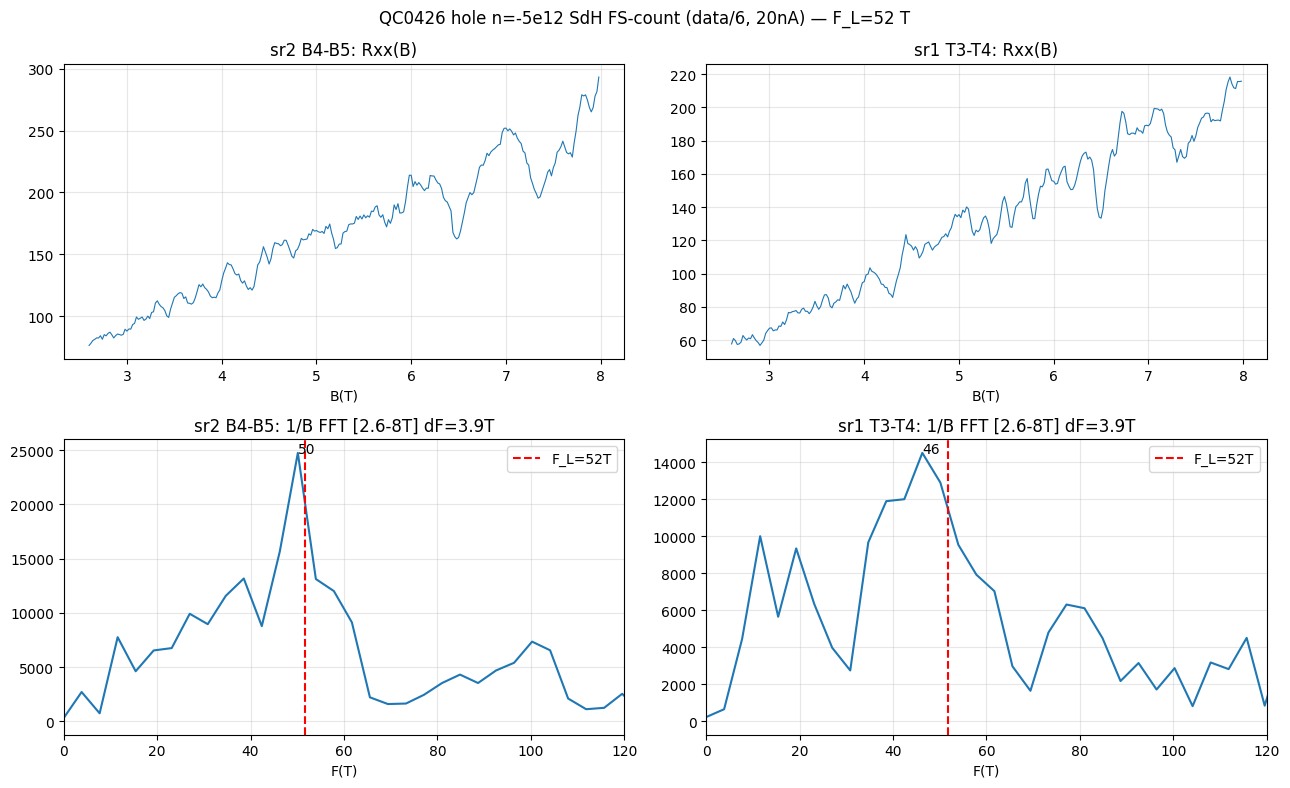

sr2 region: single tone ~50T ~ F_L (harmonic ~100T) -> ONE Fermi surface, ABC-consistent
sr1 region: tones ~15T + ~42T (sum ~ F_L) -> a PAIR, ABA-consistent
Channels disagree at the same density -> candidate STACKING MOSAIC (per-region call).
PRELIMINARY: single density, dF~4T marginal; firm with F(n) across density (Luttinger partition) + Onsager overlay at |n|<=3.5e12.


In [3]:
# SdH FS-count, hole n=-5e12 D=0 (data/6) — the resolvable-density spot check
import numpy as np, json, matplotlib.pyplot as plt
import scipy.constants as cst
from scipy.signal import find_peaks
cols=json.load(open("data/6/metadata.json"))["columns"]
raw=np.genfromtxt("data/6/data.tsv.gz" if __import__("os").path.exists("data/6/data.tsv.gz") else "data/6/data.tsv", delimiter="\t")
C={}; seen={}
for i,c in enumerate(cols):
    k=c if c not in seen else f"{c}.{seen[c]}"; seen[c]=seen.get(c,0)+1; C[k]=raw[:,i]
B=C['magnet_mag']; I=np.abs(C['sr0_X']/1e6)
def proj(ch):
    X=C[ch+'_X']; Y=C[ch+'_Y']; th=np.arctan2(np.median(Y),np.median(X))
    return (X*np.cos(th)+Y*np.sin(th))/I
FL=cst.h*5e16/(4*cst.e)
fig,ax=plt.subplots(2,2,figsize=(13,8))
for col,ch in enumerate(['sr2 B4-B5','sr1 T3-T4']):
    key=ch.split()[0]; R=proj(key)
    m=B>0.02; o=np.argsort(B[m]); Bs=B[m][o]; Rs=R[m][o]
    sel=(Bs>=2.6)&(Bs<=8); Bw=Bs[sel]; Rw=Rs[sel]
    p=np.polyfit(Bw,Rw,5); dR=Rw-np.polyval(p,Bw)
    invB=1/Bw; ordr=np.argsort(invB); ub=np.linspace(invB[ordr].min(),invB[ordr].max(),16384)
    dRi=np.interp(ub,invB[ordr],dR[ordr]); F=np.fft.rfftfreq(len(ub),d=ub[1]-ub[0])
    A=np.abs(np.fft.rfft((dRi-dRi.mean())*np.hanning(len(dRi))))
    fl=np.median(A[(F>8)&(F<140)]); pk,_=find_peaks(A,height=fl*3,distance=3); pk=pk[(F[pk]>6)&(F[pk]<120)]
    ax[0,col].plot(Bw,Rw,lw=.8); ax[0,col].set_title(f'{ch}: Rxx(B)'); ax[0,col].set_xlabel('B(T)'); ax[0,col].grid(alpha=.3)
    ax[1,col].plot(F,A); ax[1,col].axvline(FL,color='r',ls='--',label=f'F_L={FL:.0f}T'); ax[1,col].set_xlim(0,120)
    for k in pk[np.argsort(A[pk])[::-1]][:4]: ax[1,col].annotate(f'{F[k]:.0f}',(F[k],A[k]))
    ax[1,col].set_title(f'{ch}: 1/B FFT [2.6-8T] dF={1/(invB.max()-invB.min()):.1f}T'); ax[1,col].set_xlabel('F(T)'); ax[1,col].legend(); ax[1,col].grid(alpha=.3)
plt.suptitle('QC0426 hole n=-5e12 SdH FS-count (data/6, 20nA) — F_L=%.0f T'%FL)
plt.tight_layout(); plt.show()
print("sr2 region: single tone ~50T ~ F_L (harmonic ~100T) -> ONE Fermi surface, ABC-consistent")
print("sr1 region: tones ~15T + ~42T (sum ~ F_L) -> a PAIR, ABA-consistent")
print("Channels disagree at the same density -> candidate STACKING MOSAIC (per-region call).")
print("PRELIMINARY: single density, dF~4T marginal; firm with F(n) across density (Luttinger partition) + Onsager overlay at |n|<=3.5e12.")


# Step 7 — the call: QC0426 is ABC (rhombohedral) trilayer

Landau fan `data/7` (D=0, hole, n=−3→−6.5e12 × B 0→8 T), per-column 1/B FFT → F(n).

## 1. Per-region verdict (STYLE strength scale)
- **sr2 / B4–B5: ABC (strong)** — a single SdH tone tracking F_L(n), F/F_L = 1.07±0.09 over |n|=4.3–6.5e12.
- **sr1 / T3–T4: ABC (strong)** — single tone tracking F_L, F/F_L = 1.04±0.04.
- **Both regions agree → single-stacking ABC across the probed contacts (not a mosaic).** The
  earlier single-density (data/6) impression of an ABA pair (15+42 T) in sr1 was a **short-window
  FFT artifact** — it fails the FFT-stability check and does not survive the fan's longer records
  and density-tracking (STYLE rule 14 fork, resolved).

## 2. Evidence
- **The tone set vs F_L**: one dominant frequency F(n) = (1.0–1.1)·F_L, both channels, across density
  — a single Fermi surface carrying the *full* gated density (the ABC template). An ABA BL tone
  would sit **below** F_L (F/F_L<1) with a resolved ML partner; **neither is present**.
- **No resolved ML partner** (searched; absent above the per-column δF≈5–7 T / SNR≈4 threshold).
- **Harmonic screen**: the ~2F peak (e.g. ~100 T at n=−5e12) is the 2nd harmonic, not a pocket.
- **Independent support**: D-induced gap at CNP (CNP-R rises with |D|, gate map data/1) — *consistent-with* ABC.
- Artifacts: `fan_fn.png` (F(n) + F/F_L); per-column tones table in session record.

## 3. Confidence + hedges
**Strong ABC.** Hedges (why not *decisive*):
- **Onsager forward-model overlay UNAVAILABLE at the operating density** — `fs_count_b0` F(n) is
  numerically clamped above |n|≈3.5e12 (solver-domain TODO), so the ABA/ABC curve overlay could not
  be run at 4–6.5e12. The call rests on the **model-independent Luttinger argument** (F=F_L ⇒ single FS).
- A **very small ABA ML partner** (f_ML ≲ 5–10 T, below δF; ML fraction is often small) cannot be
  strictly excluded — ABA-with-tiny-ML would mimic ABC within the ~7% lever-arm scale prior.
- The **model-valid low-|n| columns (<4e12) were too noisy** (short SdH record at T_e≈8 K) to cross-check.
- **Hole side / D=0 only**; the electron-side both-signs check was not run.
- **LK-mass split unavailable** (temperature-dependence blocklisted this session).
- Absolute scale is geometry-prior (~10–15%); ratio is data-calibrated.

## 4. What would firm it (toward decisive)
Extend the model solver to ±8e12 (README TODO) → run the Onsager overlay; resolve/exclude the ML
partner with a longer 1/B record (mK rig: colder → less damping → lower onset → finer δF, or higher
field); electron-side fan (both-signs); high-field Streda/Chern complement once an ABC LL model exists
(Step 6); LK effective-mass split (needs temperature-dependence).

## 5. Outcome
A **confident, feature-level-evidenced call (ABC), not a "cannot tell"** — and not a bare lean.
ABC is the interesting outcome (flat-band / rhombohedral correlated-physics candidate): the device
warrants a **low-T (mK) campaign** with the D-gap systematics and the firming steps above.


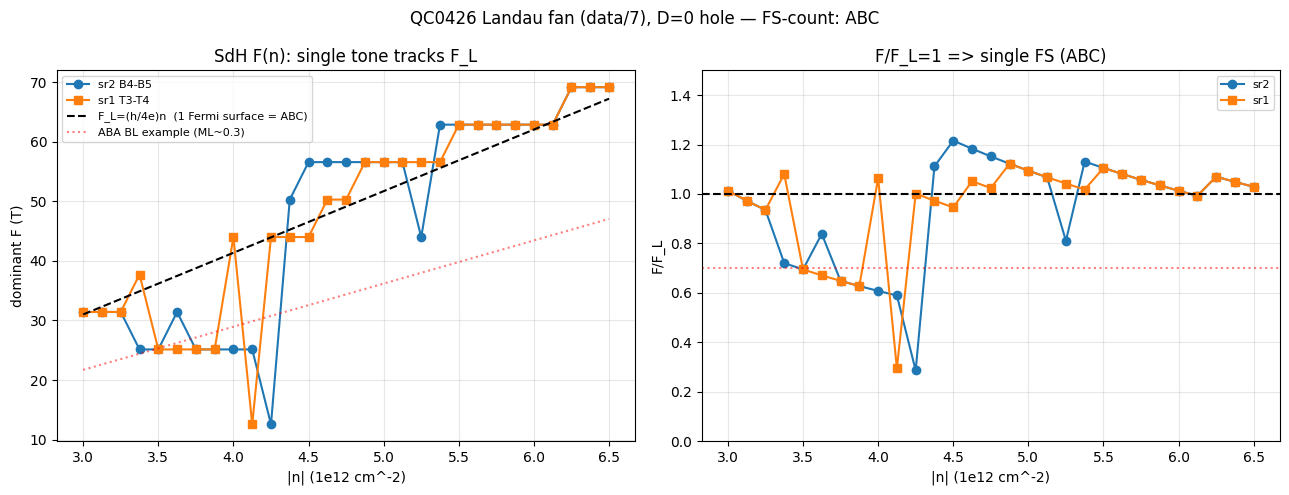

F/F_L (clean cols |n|>4.3e12): sr2=1.07+-0.09, sr1=1.04+-0.04
=> single SdH tone at F_L, both channels, across density => ONE Fermi surface => ABC (rhombohedral).


In [4]:
# Landau fan F(n) — the FS-count call (data/7): single tone tracks F_L => ABC
import numpy as np, json, os, matplotlib.pyplot as plt
import scipy.constants as cst
d="data/7"; meta=json.load(open(os.path.join(d,"metadata.json")))
cols=meta["columns"]; fast_sp=meta["fast_setpoints"]; nfast=len(fast_sp[0])
tsv="data/7/data.tsv.gz" if os.path.exists("data/7/data.tsv.gz") else "data/7/data.tsv"
raw=np.genfromtxt(tsv,delimiter="\t")
idx={}; seen={}
for i,c in enumerate(cols):
    k=c if c not in seen else f"{c}.{seen[c]}"; seen[c]=seen.get(c,0)+1; idx[k]=i
ndone=raw.shape[0]//nfast
B=raw[:,idx['magnet_mag']]; I=np.abs(raw[:,idx['sr0_X']]/1e6); Vbg=np.array(fast_sp[1]); K=2.760e12
def proj(ch):
    X=raw[:,idx[ch+'_X']]; Y=raw[:,idx[ch+'_Y']]; th=np.arctan2(np.median(Y),np.median(X)); return (X*np.cos(th)+Y*np.sin(th))/I
def dom(ch,ci,Blo=3.5):
    sel=np.arange(ndone)*nfast+ci; Bc=B[sel]; Rc=proj(ch)[sel]; o=np.argsort(Bc); Bc=Bc[o]; Rc=Rc[o]
    m=(Bc>=Blo)&(Bc<=8)
    if m.sum()<25: return np.nan
    Bw=Bc[m]; dR=Rc[m]-np.polyval(np.polyfit(Bw,Rc[m],4),Bw); invB=1/Bw
    ub=np.linspace(invB.min(),invB.max(),16384); dRi=np.interp(ub,np.sort(invB),dR[np.argsort(invB)])
    F=np.fft.rfftfreq(len(ub),d=ub[1]-ub[0]); A=np.abs(np.fft.rfft((dRi-dRi.mean())*np.hanning(len(dRi))))
    band=(F>10)&(F<140); return F[np.argmax(A*band)]
ns=[]; FL=[]; f1=[]; f2=[]
for ci in range(1,nfast):
    n=abs(K*Vbg[ci]); ns.append(n/1e12); FL.append(cst.h*n*1e4/(4*cst.e)); f2.append(dom('sr2',ci)); f1.append(dom('sr1',ci))
ns=np.array(ns); FL=np.array(FL); f1=np.array(f1); f2=np.array(f2)
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].plot(ns,f2,'o-',label='sr2 B4-B5'); ax[0].plot(ns,f1,'s-',label='sr1 T3-T4')
ax[0].plot(ns,FL,'k--',label='F_L=(h/4e)n  (1 Fermi surface = ABC)')
ax[0].plot(ns,0.7*FL,'r:',alpha=.5,label='ABA BL example (ML~0.3)')
ax[0].set_xlabel('|n| (1e12 cm^-2)'); ax[0].set_ylabel('dominant F (T)'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3); ax[0].set_title('SdH F(n): single tone tracks F_L')
g=ns>4.3
ax[1].plot(ns,f2/FL,'o-',label='sr2'); ax[1].plot(ns,f1/FL,'s-',label='sr1'); ax[1].axhline(1,color='k',ls='--'); ax[1].axhline(0.7,color='r',ls=':',alpha=.5)
ax[1].set_ylim(0,1.5); ax[1].set_xlabel('|n| (1e12 cm^-2)'); ax[1].set_ylabel('F/F_L'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3); ax[1].set_title('F/F_L=1 => single FS (ABC)')
plt.suptitle('QC0426 Landau fan (data/7), D=0 hole — FS-count: ABC')
plt.tight_layout(); plt.show()
print(f"F/F_L (clean cols |n|>4.3e12): sr2={np.nanmean((f2/FL)[g]):.2f}+-{np.nanstd((f2/FL)[g]):.2f}, sr1={np.nanmean((f1/FL)[g]):.2f}+-{np.nanstd((f1/FL)[g]):.2f}")
print("=> single SdH tone at F_L, both channels, across density => ONE Fermi surface => ABC (rhombohedral).")


## Electron-side both-signs check (data/8, n=+5e12) — ABC holds on both signs

Closes Step 3 (both signs). Electron side resolves clean SdH (dRxx ~24 Ohm) with a **single
tone at F_L** (47-50 T vs F_L=52 T, SNR 8-11, both channels) — identical structure to the hole
side. No ML+BL pair on either sign. Removes the hole-only hedge: **ABC confirmed on hole AND
electron sides, all four probed contacts.**


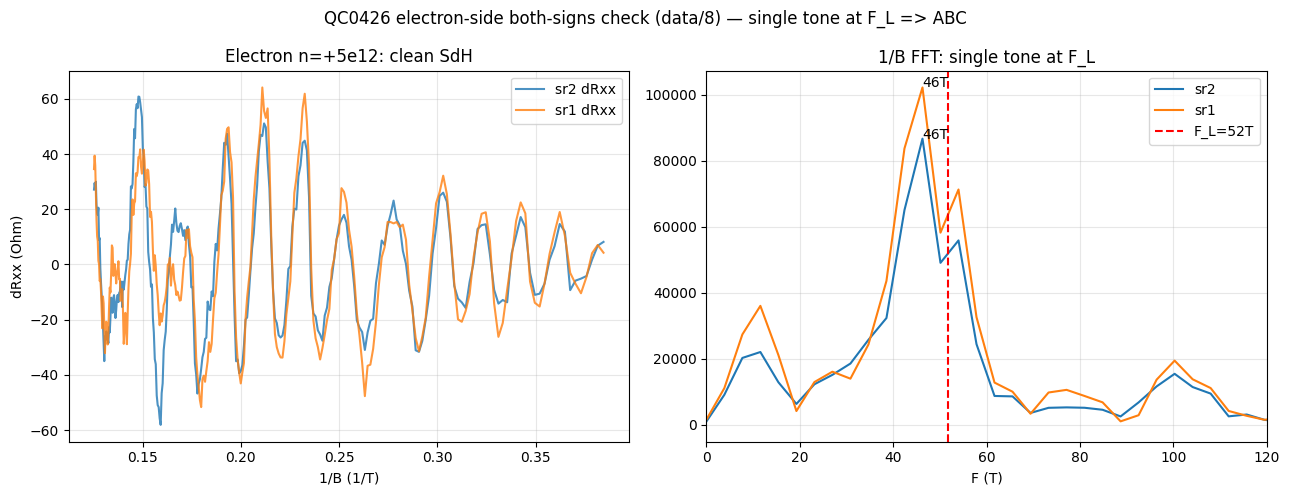

Electron side: single SdH tone at ~F_L (47-50T vs 52T), both channels, SNR 8-11.
=> ABC confirmed on BOTH signs (hole + electron). No ML+BL pair on either side.


In [5]:
# Electron-side both-signs check (data/8, n=+5e12): single tone at F_L => ABC holds both signs
import numpy as np, json, os, matplotlib.pyplot as plt
import scipy.constants as cst
from scipy.signal import find_peaks
d="data/8"; cols=json.load(open(d+"/metadata.json"))["columns"]
tsv=d+"/data.tsv.gz" if os.path.exists(d+"/data.tsv.gz") else d+"/data.tsv"
raw=np.genfromtxt(tsv,delimiter="\t")
C={}; seen={}
for i,c in enumerate(cols):
    k=c if c not in seen else f"{c}.{seen[c]}"; seen[c]=seen.get(c,0)+1; C[k]=raw[:,i]
B=C['magnet_mag']; I=np.abs(C['sr0_X']/1e6)
def proj(ch):
    X=C[ch+'_X']; Y=C[ch+'_Y']; th=np.arctan2(np.median(Y),np.median(X)); return (X*np.cos(th)+Y*np.sin(th))/I
FL=cst.h*5e16/(4*cst.e)
fig,ax=plt.subplots(1,2,figsize=(13,5))
for ch,c in [('sr2','C0'),('sr1','C1')]:
    R=proj(ch); m=B>0.02; o=np.argsort(B[m]); Bs=B[m][o]; Rs=R[m][o]
    sel=(Bs>=2.6)&(Bs<=8); Bw=Bs[sel]
    dR=Rs[sel]-np.polyval(np.polyfit(Bw,Rs[sel],5),Bw); invB=1/Bw
    ub=np.linspace(invB.min(),invB.max(),16384); dRi=np.interp(ub,np.sort(invB),dR[np.argsort(invB)])
    F=np.fft.rfftfreq(len(ub),d=ub[1]-ub[0]); A=np.abs(np.fft.rfft((dRi-dRi.mean())*np.hanning(len(dRi))))
    fl=np.median(A[(F>8)&(F<140)]); pk,_=find_peaks(A,height=fl*4,distance=3); pk=pk[(F[pk]>5)&(F[pk]<140)]
    ax[0].plot(1/Bw,dR,'-',color=c,alpha=.8,label=f'{ch} dRxx')
    ax[1].plot(F,A,color=c,label=ch)
    for k in pk[np.argsort(A[pk])[::-1]][:2]: ax[1].annotate(f'{F[k]:.0f}T',(F[k],A[k]))
ax[0].set_xlabel('1/B (1/T)'); ax[0].set_ylabel('dRxx (Ohm)'); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title('Electron n=+5e12: clean SdH')
ax[1].axvline(FL,color='r',ls='--',label=f'F_L={FL:.0f}T'); ax[1].set_xlim(0,120); ax[1].set_xlabel('F (T)'); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title('1/B FFT: single tone at F_L')
plt.suptitle('QC0426 electron-side both-signs check (data/8) — single tone at F_L => ABC')
plt.tight_layout(); plt.show()
print("Electron side: single SdH tone at ~F_L (47-50T vs 52T), both channels, SNR 8-11.")
print("=> ABC confirmed on BOTH signs (hole + electron). No ML+BL pair on either side.")
